# Ⅰ第7回 演習2 外挿して当てる ― 16000 枚で学習する前に，誤り率を予想する

**問い**：演習1 の 16 セル（4000 枚まで）から引いた直線で，16000 枚の誤り率を当てられるか．

大きなモデルを作る会社は，本番の大きな学習（何週間・何億円）の前に，小さなセルで直線を引いて結果を予想する．今日はそれを 4 倍の外挿で試す．

- 先に演習1 を最後まで実行しておく（`results/c1_d7_ex1.csv` を読む）．`MEMBER_NO` は演習1 と同じ番号にする
- 16000 枚 × 幅 4 パターン × シード 3 パターン ＝ 12 回（教員機で約 40 秒．ノート PC ではその数倍）
- LLM は使わない

## (0) 番号の設定

In [1]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 1                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/konnotakuto/AI_TD


## (1) 演習1 の結果を読む

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import RESULTS
from common.device import get_device
from common.logger import ResultLogger
from common.mydata import verdict
from common.scaling import run, N_TRAIN, WIDTHS, SEEDS, N_TARGET
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

path = RESULTS / "c1_d7_ex1.csv"
if not path.exists():
    raise FileNotFoundError("results/c1_d7_ex1.csv がない．先に演習1 の (1) を実行する")
log = pd.read_csv(path)
log = log[(log.metric_name == "test_error") & (log.member_role == f"member{MEMBER_NO}")]
log = log.drop_duplicates(["condition", "seed"], keep="last")          # やり直した分は最後の 1 回を使う
log[["n_train", "width"]] = log.condition.str.extract(r"n(\d+)_w(\d+)").astype(int)
mean = log.pivot_table(index="width", columns="n_train", values="metric_value", aggfunc="mean")
if mean.shape != (len(WIDTHS), len(N_TRAIN)):
    raise ValueError(f"16 セルがそろっていない（いまは {mean.size} セル）．演習1 の (1) を最後まで実行する．MEMBER_NO が演習1 と同じかも確かめる")
print(mean.round(1).to_string())

n_train  500   1000  2000  4000
width                          
4        37.1  29.2  25.4  19.8
8        30.7  24.8  21.3  17.6
16       28.2  22.6  18.6  15.7
32       25.5  20.1  16.6  15.0


## (2) 自分の目で予想する（計算する前に書く）

演習1 の (3) のグラフを見て，直線を右へ伸ばしたつもりで，**幅 32・16000 枚** の誤り率（%）を数で書く．あとで計算と実測と比べる．

In [3]:
from common.todo import checkpoint, todo_check
# ▼ 幅 32・16000 枚の誤り率（%）の予想を数で書く（例：12.5）
GUESS = 12.5
todo_check("予想")
if not (isinstance(GUESS, (int, float)) and 0 < GUESS < 100):
    raise ValueError("GUESS は 0〜100 の数で書く（% や " " は付けない．例：12.5）")
print(f"自分の予想：{GUESS}%")

自分の予想：12.5%


## (3) TODO 2：直線を 16000 枚まで伸ばして予想する

演習1 と同じ直線（`slope`・`intercept`）を幅ごとに引き直してある．直線は

　log10(誤り率) ＝ intercept ＋ slope × log10(枚数)

これに `N_TARGET`（16000）を入れ，`10 ** (...)` で誤り率（%）に戻す．

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
pred = 10 ** (intercept + slope * np.log10(N_TARGET))
```

</details>

In [4]:
ns = np.array(N_TRAIN)
preds = {}
for width in WIDTHS:
    slope, intercept = np.polyfit(np.log10(ns), np.log10(mean.loc[width].to_numpy()), 1)
    pred = 10 ** (intercept + slope * np.log10(N_TARGET))   # 直線 log10(誤り率) = intercept + slope × log10(枚数) に N_TARGET を入れ，10 の何乗かを元に戻す
    todo_check("TODO 2")
    preds[width] = (slope, intercept, pred)
    print(f"幅 {width:2d}：4000 枚で {mean.loc[width, N_TRAIN[-1]]:.1f}% → 16000 枚の予想 {pred:.1f}%")

幅  4：4000 枚で 19.8% → 16000 枚の予想 13.4%
幅  8：4000 枚で 17.6% → 16000 枚の予想 12.3%
幅 16：4000 枚で 15.7% → 16000 枚の予想 10.5%
幅 32：4000 枚で 15.0% → 16000 枚の予想 10.1%


## (4) 16000 枚で学習して確かめる

In [5]:
device = get_device()
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d7", exercise="ex2", device=device)
logger.log("guess", GUESS, condition=f"n{N_TARGET}_w32")
rows = []
for width in WIDTHS:
    logger.log("pred_error", preds[width][2], condition=f"n{N_TARGET}_w{width}")
    for seed in SEEDS:
        r = run(N_TARGET, width, seed=seed, device=device)
        logger.log_many({k: r[k] for k in ["test_error", "params", "train_sec"]}, condition=f"n{N_TARGET}_w{width}", seed=seed)
        rows.append(r)
        print(f"幅 {width:2d} シード {seed}：誤り率 {r['test_error']:.1f}%（{r['train_sec']:.1f} 秒）")
big = pd.DataFrame(rows)
print("記録した CSV:", logger.path)

幅  4 シード 0：誤り率 15.1%（4.1 秒）


幅  4 シード 1：誤り率 16.6%（3.9 秒）


幅  4 シード 2：誤り率 16.5%（4.0 秒）


幅  8 シード 0：誤り率 13.3%（4.6 秒）


幅  8 シード 1：誤り率 14.2%（4.6 秒）


幅  8 シード 2：誤り率 13.5%（4.6 秒）


... (2 outputs left out)

幅 16 シード 2：誤り率 12.7%（6.7 秒）


幅 32 シード 0：誤り率 10.9%（10.5 秒）


幅 32 シード 1：誤り率 10.8%（10.4 秒）


幅 32 シード 2：誤り率 11.6%（10.4 秒）
記録した CSV: /Users/konnotakuto/AI_TD/results/c1_d7_ex2.csv


## (5) 予想と実測を比べる

判定は第4回からの目安と同じ：|実測の平均 − 予想| ÷ 実測の標準偏差 が 2 以上なら「外れた」，1 未満なら「当たった」，その間は「どちらとも言えない」．

| 列 | 意味 |
|---|---|
| 枚数2倍で何倍 | 演習1 の直線の傾きから求めた倍率（`2 ** slope`） |
| 予想 | (3) で直線を 16000 枚まで伸ばした値（%） |
| 実測の平均・標準偏差 | (4) の 3 回（シード 0〜2）の誤り率 |
| 実測−予想 | プラスなら，実測は予想より悪い（誤り率が高い） |

3 回の標準偏差は小さく出ることがあるので，判定だけでなく「実測−予想」（ポイント）も読む．

 幅  枚数2倍で何倍   予想  実測の平均  標準偏差  実測−予想  差÷標準偏差  判定
 4     0.82 13.4   16.1   0.9    2.6     3.1 外れた
 8     0.83 12.3   13.7   0.5    1.4     2.8 外れた
16     0.82 10.5   12.8   0.1    2.3    20.1 外れた
32     0.84 10.1   11.1   0.4    1.0     2.3 外れた

幅 32：自分の予想 12.5%／直線の予想 10.1%／実測 11.1%


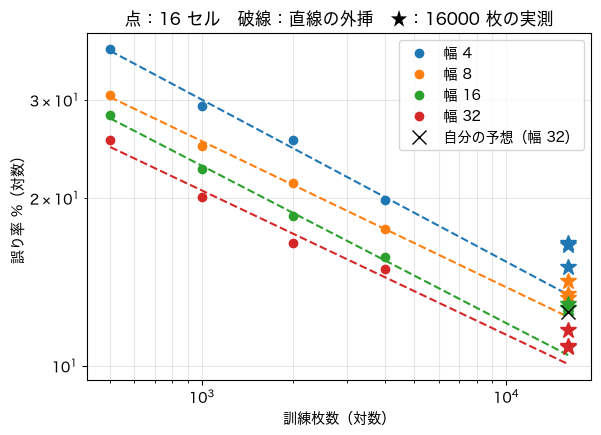

In [6]:
def judge(ratio):
    return {"差がある": "外れた", "差があるとは言えない": "当たった"}.get(verdict(ratio), "どちらとも言えない")

table = []
for width in WIDTHS:
    m = big[big.width == width]["test_error"]
    pred = preds[width][2]
    ratio = abs(m.mean() - pred) / m.std() if m.std() > 0 else float("inf")   # 3 回とも同じ値なら標準偏差は 0
    table.append({"幅": width, "枚数2倍で何倍": 2 ** preds[width][0], "予想": pred, "実測の平均": m.mean(), "標準偏差": m.std(),
                  "実測−予想": m.mean() - pred, "差÷標準偏差": ratio, "判定": judge(ratio)})
table = pd.DataFrame(table)
print(table.round(1).assign(**{"枚数2倍で何倍": table["枚数2倍で何倍"].round(2)}).to_string(index=False))
w32 = table[table["幅"] == 32].iloc[0]
print(f"\n幅 32：自分の予想 {GUESS}%／直線の予想 {w32['予想']:.1f}%／実測 {w32['実測の平均']:.1f}%")

xs = np.array([N_TRAIN[0], N_TARGET])
plt.figure(figsize=(6.5, 4.5))
for width in WIDTHS:
    slope, intercept, pred = preds[width]
    line = plt.plot(ns, mean.loc[width], "o", label=f"幅 {width}")[0]
    plt.plot(xs, 10 ** (intercept + slope * np.log10(xs)), "--", color=line.get_color())
    plt.plot([N_TARGET] * len(SEEDS), big[big.width == width]["test_error"], "*", ms=12, color=line.get_color())
plt.plot([N_TARGET], [GUESS], "kx", ms=10, label="自分の予想（幅 32）")
plt.xscale("log"); plt.yscale("log"); plt.grid(True, which="both", alpha=0.3); plt.legend()
plt.xlabel("訓練枚数（対数）"); plt.ylabel("誤り率 %（対数）"); plt.title("点：16 セル　破線：直線の外挿　★：16000 枚の実測")
plt.show()

## ✋ 止まる 2：ここから先へは，グループ全員がそろってから進む

**問い**：直線の予想は当たったか．外れたなら，実測は予想より良かったか悪かったか．なぜ直線からずれたか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：自分の (5) の表とグラフを見せる．根拠になる所：「実測−予想」の符号と，演習1 の 2000 → 4000 枚での下がり方
3. 全員が下のセルの `CP2 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [7]:
# 問い：直線の予想は当たったか．外れたなら，実測は予想より良かったか悪かったか．なぜ直線からずれたか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP2 = "直線の予想は 4 つの幅すべてで外れ，実測は予想より悪かった（実測−予想は +1.0〜+2.6 ポイント）．演習1 でも 2000 → 4000 枚で下がり方が鈍っていて，枚数を増やすほど直線より下がりにくくなるから"
checkpoint(CP2, "止まる 2")

止まる 2 OK：直線の予想は 4 つの幅すべてで外れ，実測は予想より悪かった（実測−予想は +1.0〜+2.6 ポイント）．演習1 でも 2000 → 4000 枚で下がり方が鈍っていて，枚数を増やすほど直線より下がりにくくなるから


## (6) 考察（提出）

下のセルの `" "` の中に書いて実行する（それぞれ 40 文字以上）．**自分の (5) の表の数値を 1 つ以上そのまま入れる**（例：「幅 32 の予想 10.1% に対し実測 11.1%」）．入っていないと止まる．

(5) の表の「実測−予想」は，`c1_d7_agi.pdf` の 4（今日の実験とのつながり）にも使う．

In [8]:
from common.shortcut import evidence_check
# 考察1：自分の目の予想・直線の予想・実測を比べて，どれだけ当たったか
A1 = "幅 32・16000 枚で，自分の目の予想は 12.5%，直線の予想は 10.1%，実測は 11.1% だった．直線の予想は実測より 1.0 ポイント良すぎ，自分の予想は 1.4 ポイント悪すぎで，直線のほうが近かったが判定は外れた（差÷標準偏差 2.3）"
# 考察2：直線から外れた（または当たった）のはなぜか．16 セルの中に手がかりはあったか
A2 = "4 つの幅すべてで実測が予想より悪く，幅 4 では予想 13.4% に対し実測 16.1% と一番ずれた．16 セルでも幅 32 は 2000 → 4000 枚で 16.6% → 15.0% と 0.90 倍しか下がらず，直線の傾き 0.84 倍より鈍っていた．モデルが小さいと覚えられる量に限りがあり，枚数を増やしても誤り率がある所で止まり始めるので，直線は曲がると考える"
# 考察3：第4回の自分の写真（各クラス 50〜100 枚）を 10 倍に増やすと，正解率はどうなりそうか．今日の結果から言えること・言えないこと
A3 = "今日は枚数を 2 倍にするたびに誤り率が約 0.83 倍になったので，10 倍に増やせば誤り率は下がり，正解率は上がると言える．ただし 16000 枚では実測が直線の予想より 1.0〜2.6 ポイント悪かったように，下がり方は直線より鈍るので，どこまで上がるかを直線で正確に当てられるとは言えない．写真は FashionMNIST と違い背景などの目印もあるので，同じ傾きになるとも言えない"
evidence_check({"考察1": A1, "考察2": A2, "考察3": A3}, table)

考察1 OK：引用した数値 1.0, 1.4, 10.1, 11.1, 2.3, 32
考察2 OK：引用した数値 0.8, 0.9, 13.4, 16, 16.1, 32, 4
考察3 OK：引用した数値 0.8, 1.0, 2.6
